# Entregable 2


**Alcance:** modelos unimodales reentrenados sobre `sub50` y prototipo de la fusión por esquema de votación.

Contenido:
1) preparación
2) exploración de datos
3) entrenamiento en sub50 con checkpoints
4) evaluación y matrices de confusión
5) fusión por votación 2-de-3
6) extracción de embeddings
7) resumen guardado en results.json

## 1. Preparación

In [1]:
!git clone https://github.com/David04Bucheli/proyecto-integrador.git
%cd proyecto-integrador

Cloning into 'proyecto-integrador'...
remote: Enumerating objects: 34, done.
remote: Counting objects: 100% (34/34), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 34 (delta 1), reused 29 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (34/34), 80.65 KiB | 16.13 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/content/proyecto-integrador


In [2]:
import os, sys, json, time, platform
from pathlib import Path

# --- Dónde está el código --------------------------------------------------
# Este notebook asume que se ejecuta desde la raíz del repositorio (donde está la carpeta src/).
# Si lo corres en otra máquina sin el repo, pon aquí la URL de tu repositorio de GitHub.
REPO_URL = ""   # p. ej. "https://github.com/<usuario>/<repo>.git"
if not os.path.isdir("src"):
    if os.path.isdir("../src"):
        os.chdir("..")
    elif REPO_URL:
        os.system(f"git clone {REPO_URL} repo_clone")
        os.chdir("repo_clone")
    else:
        raise RuntimeError("No encuentro la carpeta src/. Ejecuta desde la raíz del repo o define REPO_URL.")
print("Directorio de trabajo:", os.getcwd())

Directorio de trabajo: /content/proyecto-integrador


In [3]:
%pip install -q -r requirements.txt

In [4]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from src import config, datasets, models, engine, embeddings, audit, runs, fusion, explore, reporting

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("torch", torch.__version__, "| python", platform.python_version())

SUBSET = config.SUBSET_FORMAL          # "sub50"
OUT = Path("outputs_e2")               # resultados de esta corrida (checkpoints y .npz están en .gitignore)
for d in ("checkpoints", "predictions", "figures", "embeddings"):
    (OUT / d).mkdir(parents=True, exist_ok=True)

Dispositivo: cuda
GPU: NVIDIA A100-SXM4-80GB
torch 2.11.0+cu130 | python 3.13.15


In [5]:
# Login de Hugging Face: opcional (el dataset es público). Si lo usas, hazlo de forma interactiva; no pegues tokens en el notebook.
# from huggingface_hub import login; login()
ds = datasets.load_subset(SUBSET)
print(ds)

README.md:   0%|          | 0.00/23.5k [00:00<?, ?B/s]

sub50_42/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  230MB            

sub50_42/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sub50_42/validation-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 29.5MB            

sub50_42/validation-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

...

sub50_42/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8526 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1071 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1111 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['photometry', 'spectra', 'metadata', 'label'],
        num_rows: 8526
    })
    validation: Dataset({
        features: ['photometry', 'spectra', 'metadata', 'label'],
        num_rows: 1071
    })
    test: Dataset({
        features: ['photometry', 'spectra', 'metadata', 'label'],
        num_rows: 1111
    })
})


### Decisiones de protocolo (fijadas antes de ver resultados)

- **Mismo protocolo que el Entregable 1:** Adam, lr 1e-3, batch 32, 20 épocas, seed 42, los mismos modelos. El modelo que se reporta como principal es el de **la última época** (igual que en el Entregable 1), para que las cifras sean comparables.
- Además se guarda el checkpoint con **mejor macro-F1 en validación** (nunca se elige con test). Queda como variante complementaria; si se usa, se declara.
- **Votación:** mayoría 2-de-3. Con 10 clases los tres modelos pueden votar clases distintas; la regla de desempate se **elige con validación** (no con test) entre: `priority` (gana la modalidad con mejor macro-F1 de validación), `confidence` (gana el modelo más seguro) y `error` (sin decisión, cuenta como error).
- Métrica principal: **macro-F1** (más accuracy y reporte por clase), porque `sub50` probablemente está desbalanceado.
- Una sola corrida por modelo (seed 42): hay no determinismo entre corridas (el tutor obtuvo valores ligeramente distintos al reproducir el Entregable 1), así que diferencias pequeñas no son concluyentes.

## 2. Exploración de datos (sub50)

,train,validation,test,total,train_%,validation_%,test_%
DSCT,206,25,24,255,2.4,2.3,2.2
EA,1209,149,160,1518,14.2,13.9,14.4
EB,1209,149,160,1518,14.2,13.9,14.4
EW,1209,149,160,1518,14.2,13.9,14.4
HADS,226,29,26,281,2.7,2.7,2.3
M,216,30,22,268,2.5,2.8,2.0
ROT,1209,149,160,1518,14.2,13.9,14.4
RRAB,1209,149,160,1518,14.2,13.9,14.4
RRC,624,93,79,796,7.3,8.7,7.1
SR,1209,149,160,1518,14.2,13.9,14.4


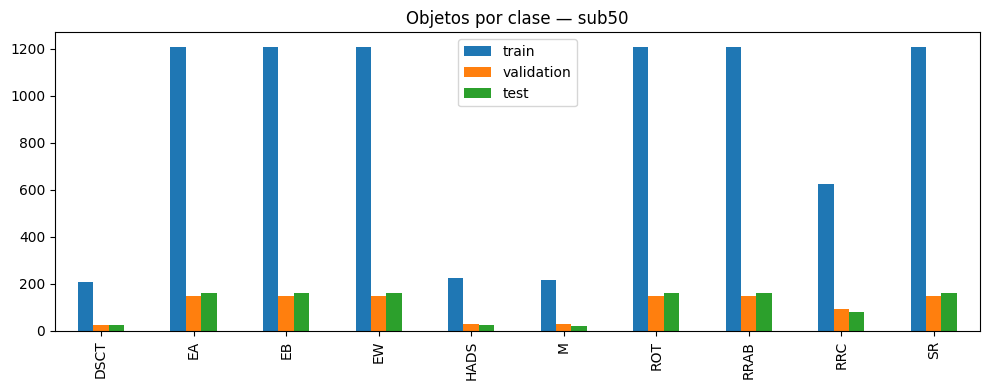

Cociente clase mayor / clase menor en train: 5.87


In [6]:
splits = {k: ds[k] for k in ("train", "validation", "test")}
dist = explore.class_distribution(splits)
display(dist)
dist[["train", "validation", "test"]].plot(kind="bar", figsize=(10, 4), title=f"Objetos por clase — {SUBSET}")
plt.tight_layout(); plt.savefig(OUT / "figures" / "distribucion_clases.png", dpi=150); plt.show()
print("Cociente clase mayor / clase menor en train:", round(dist["train"].max() / dist["train"].min(), 2))

count    8526.000000
mean      249.343186
std       112.436386
min        33.000000
25%       179.250000
50%       222.000000
75%       272.000000
max       964.000000
Name: longitud, dtype: float64
Fracción de curvas con la longitud máxima: 0.0


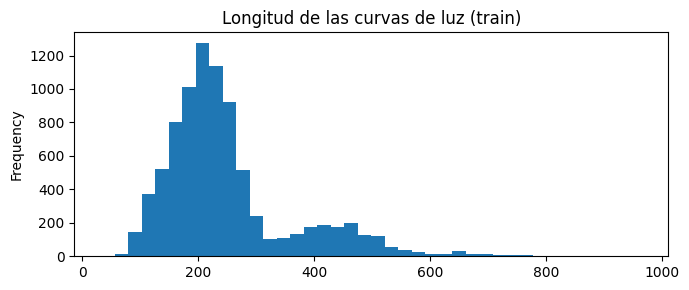

In [7]:
lens = explore.photometry_lengths(ds["train"])
print(lens.describe())
print("Fracción de curvas con la longitud máxima:", round((lens == lens.max()).mean(), 3))
lens.plot(kind="hist", bins=40, figsize=(7, 3), title="Longitud de las curvas de luz (train)")
plt.tight_layout(); plt.savefig(OUT / "figures" / "longitud_curvas.png", dpi=150); plt.show()

In [8]:
# ¿Qué son los 9 canales de la fotometría? Se mide, no se asume.
# Un canal 'constante en la curva' para (casi) todos los objetos es un valor por objeto (p. ej. período, amplitud),
# no una señal que cambia en el tiempo. Esto confirma o descarta la sospecha del tutor sobre los canales auxiliares.
phot_stats = explore.photometry_channel_stats(ds["train"], n=2000)
display(phot_stats)

,media,desv,min,max,frac_objetos_constante_en_la_curva,n_nan
canal,,,,,,
0,4.978885e-01,0.253974,0.000000,1.000000,0.0,0
1,-5.552913e-10,2.622412,-115.437210,137.764221,0.0,0
2,5.549365e-01,0.387791,0.000000,5.739436,0.0,0
3,5.576955e-02,1.031605,-0.846839,8.971242,1.0,0
4,-6.164788e-03,1.008240,-1.625038,2.794415,1.0,0
5,1.607677e-02,0.987535,-1.168374,3.110190,1.0,0
6,-3.837734e-02,1.008654,-3.588042,1.167856,1.0,0
7,-2.125455e-01,0.499371,-1.102373,2.228156,1.0,0
8,4.990872e+00,0.866938,2.563014,6.863698,1.0,0


In [9]:
spec_stats = explore.spectra_channel_stats(ds["train"], n=1000)
display(spec_stats)   # escalas por canal, ceros, NaN: insumo para diagnosticar la CNN de espectros

,media,desv,min,max,media_de_la_desv_por_objeto,frac_ceros,n_nan
canal,,,,,,,
0,-2.620493e-11,2.766400,-51.409737,249.585938,1.958162,0.000000,0
1,5.338199e-03,0.055206,0.000000,4.878068,0.004979,0.008285,0
2,2.323300e+00,0.825220,-0.110215,4.776920,0.000000,0.000000,0


In [10]:
meta_stats = explore.metadata_stats(ds["train"])
display(meta_stats)
print("Columnas constantes:", int(meta_stats["constante"].sum()), "| NaN totales:", int(meta_stats["n_nan"].sum()))

,media,desv,min,max,n_nan,constante
columna,,,,,,
0,2.509753e-10,1.0,-4.790176,3.739488,0,False
1,6.093926e-10,1.0,-5.211874,3.142027,0,False
2,-2.572050e-10,1.0,-0.787118,15.509432,0,False
3,-4.248443e-10,1.0,-4.429221,3.704809,0,False
4,-1.323651e-10,1.0,-0.590647,17.180090,0,False
5,-2.854538e-10,1.0,-5.408902,2.819384,0,False
6,1.146695e-10,1.0,-0.828381,13.051200,0,False
7,-4.647842e-10,1.0,-1.181405,5.634689,0,False
8,3.687475e-11,1.0,-1.450747,28.415527,0,False


Columnas constantes: 0 | NaN totales: 0


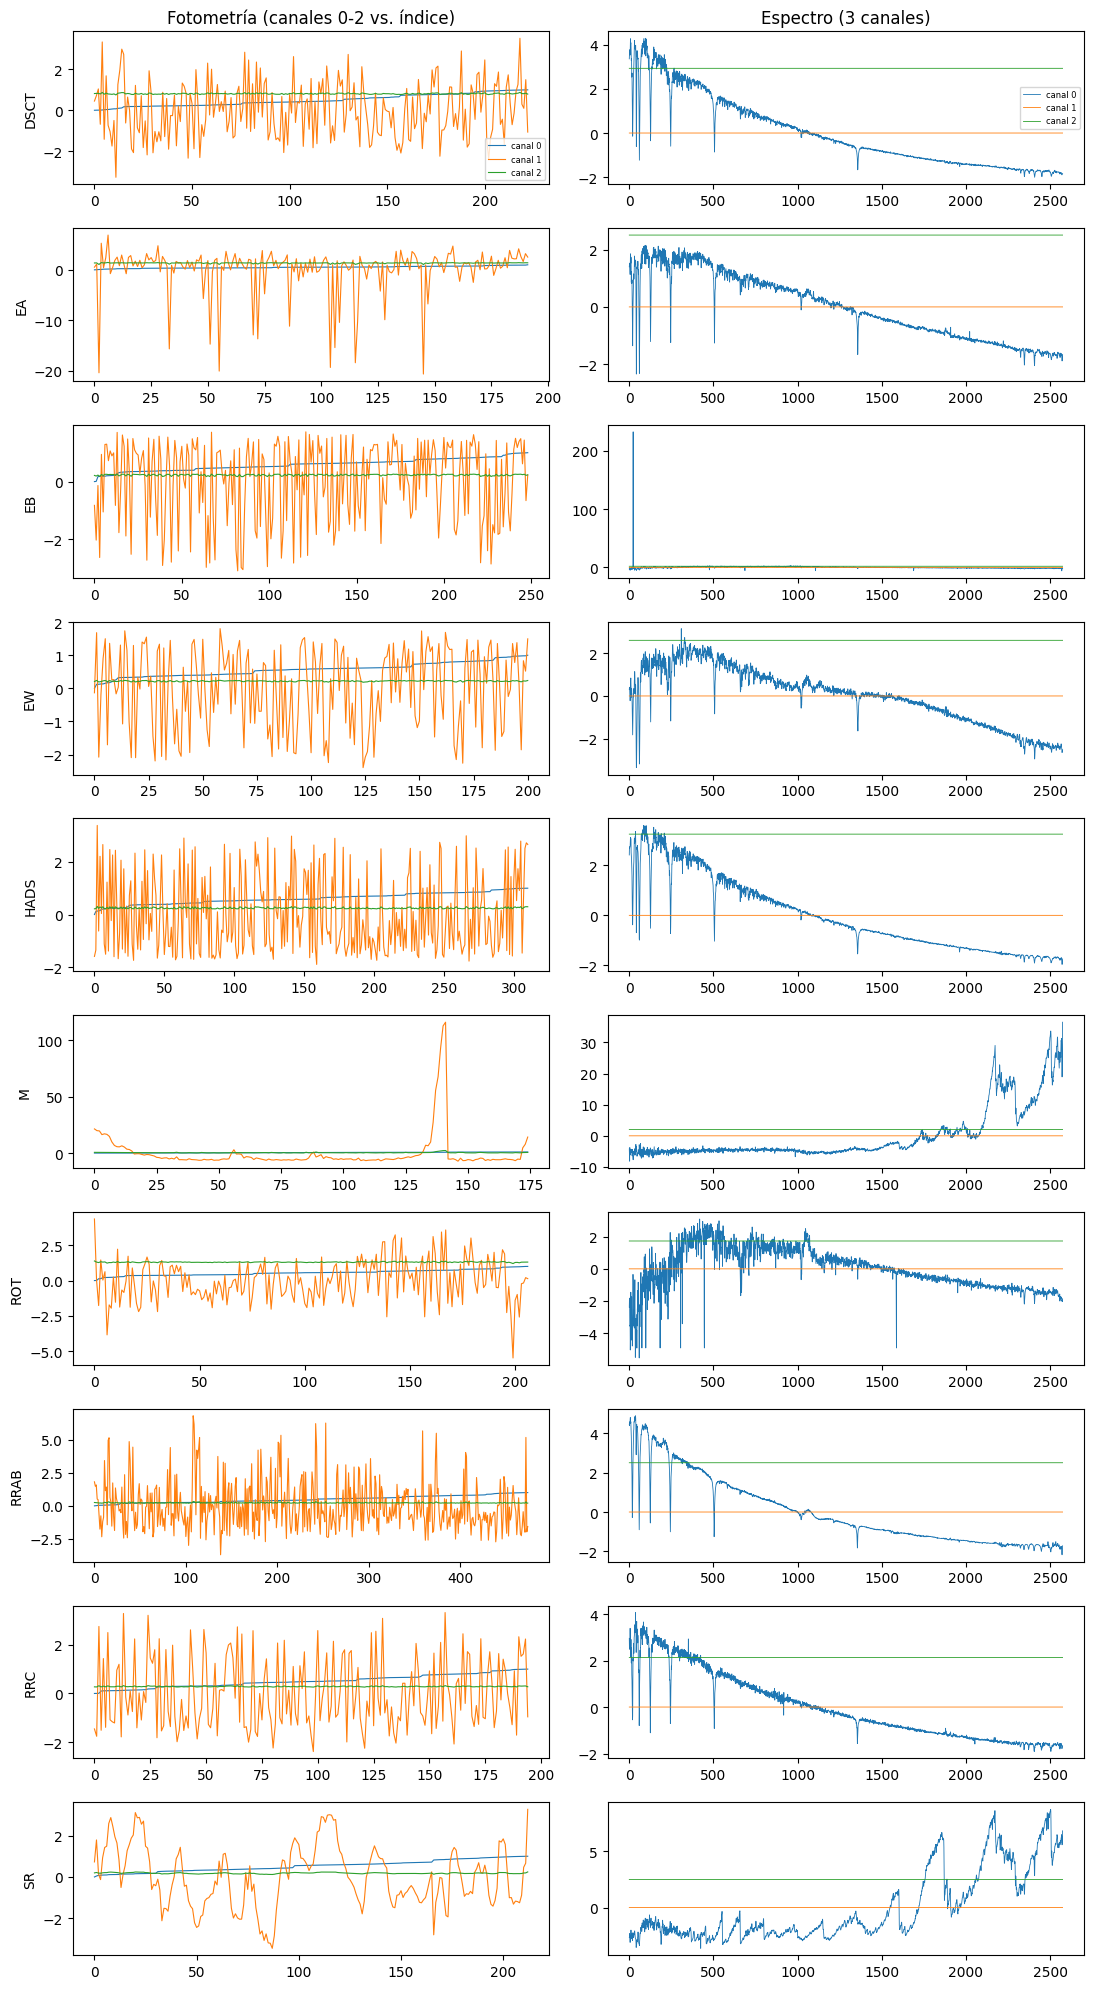

In [11]:
# Un ejemplo por clase (primer objeto de cada clase en train): primeros canales de la curva y espectro.
first = explore.first_example_per_class(ds["train"])
fig, axes = plt.subplots(len(first), 2, figsize=(11, 2.0 * len(first)))
for r, (c, idx) in enumerate(first.items()):
    row = ds["train"][idx]
    ph = np.asarray(row["photometry"]); sp = np.asarray(row["spectra"])
    for ch in range(min(3, ph.shape[1])):
        axes[r, 0].plot(ph[:, ch], lw=0.8, label=f"canal {ch}")
    axes[r, 0].set_ylabel(config.CLASS_NAMES[c])
    for ch in range(sp.shape[0]):
        axes[r, 1].plot(sp[ch], lw=0.6, label=f"canal {ch}")
axes[0, 0].set_title("Fotometría (canales 0-2 vs. índice)"); axes[0, 1].set_title("Espectro (3 canales)")
axes[0, 0].legend(fontsize=6); axes[0, 1].legend(fontsize=6)
plt.tight_layout(); plt.savefig(OUT / "figures" / "ejemplos_por_clase.png", dpi=130); plt.show()

**Anotar aquí lo que muestran las tablas** (después de ejecutar): qué canales de la fotometría son constantes por objeto, escalas de los 3 canales del espectro, columnas de metadatos constantes o con NaN, grado de desbalance. Esto cierra la deuda de exploración del Entregable 1 y orienta la revisión de la CNN (el tutor pidió revisarla): si los canales del espectro tienen escalas muy distintas o los espectros no están normalizados, es una hipótesis concreta; **no se modifica la CNN sin evidencia y sin registrarlo**.

## 3. Entrenamiento de los tres baselines sobre sub50 (con checkpoints)

In [12]:
NAMES = ["fotometria", "espectros", "metadatos"]
FWD = {"fotometria": engine.forward_fn_photometry,
       "espectros": engine.forward_fn_spectra,
       "metadatos": engine.forward_fn_metadata}
META_DIM = len(ds["train"][0]["metadata"])

def build(name):
    torch.manual_seed(config.SEED)                      # misma semilla antes de construir cada modelo
    if name == "fotometria":
        enc = models.PhotometryGRUEncoder(input_dim=len(ds["train"][0]["photometry"][0]))
    elif name == "espectros":
        enc = models.SpectraCNNEncoder(in_channels=len(ds["train"][0]["spectra"]))
    else:
        enc = models.MetadataMLPEncoder(input_dim=META_DIM)
    return models.UnimodalClassifier(enc)

train_loader = datasets.make_dataloader(ds["train"], shuffle=True)
val_loader = datasets.make_dataloader(ds["validation"], shuffle=False)
fit_results, MODELS = {}, {}
for name in NAMES:
    print(f"\n===== {name} =====")
    torch.manual_seed(config.SEED)
    model = build(name)
    fit_results[name] = runs.fit_with_checkpoints(model, train_loader, val_loader, FWD[name],
                                                  device=DEVICE, class_names=config.CLASS_NAMES)
    runs.save_checkpoint(OUT / "checkpoints" / f"{name}_{SUBSET}.pt", fit_results[name],
                         extra={"seed": config.SEED, "subset": SUBSET})
    runs.save_history_json(OUT / f"history_{name}_{SUBSET}.json", fit_results[name]["history"],
                           extra={"train_seconds": fit_results[name]["train_seconds"],
                                  "n_parameters": fit_results[name]["n_parameters"],
                                  "best_epoch_val_macro_f1": fit_results[name]["best_epoch"]})
    MODELS[name] = model
    print(f"{name}: {fit_results[name]['train_seconds']:.0f} s | {fit_results[name]['n_parameters']:,} parámetros | mejor época (val macro-F1): {fit_results[name]['best_epoch']}")


===== fotometria =====
[01/20] train_loss=0.9299 train_acc=0.666 | val_loss=0.6202 val_acc=0.776 val_macroF1=0.787
[02/20] train_loss=0.5417 train_acc=0.797 | val_loss=0.5772 val_acc=0.780 val_macroF1=0.795
[03/20] train_loss=0.4953 train_acc=0.804 | val_loss=0.4613 val_acc=0.821 val_macroF1=0.821
[04/20] train_loss=0.4459 train_acc=0.825 | val_loss=0.4493 val_acc=0.811 val_macroF1=0.814
[05/20] train_loss=0.4133 train_acc=0.844 | val_loss=0.3948 val_acc=0.849 val_macroF1=0.860
[06/20] train_loss=0.3781 train_acc=0.857 | val_loss=0.3542 val_acc=0.865 val_macroF1=0.871
[07/20] train_loss=0.3532 train_acc=0.865 | val_loss=0.3875 val_acc=0.852 val_macroF1=0.867
[08/20] train_loss=0.3449 train_acc=0.870 | val_loss=0.3538 val_acc=0.866 val_macroF1=0.872
[09/20] train_loss=0.3248 train_acc=0.878 | val_loss=0.4092 val_acc=0.844 val_macroF1=0.843
[10/20] train_loss=0.3221 train_acc=0.877 | val_loss=0.3396 val_acc=0.873 val_macroF1=0.871
[11/20] train_loss=0.3137 train_acc=0.883 | val_loss=0.3

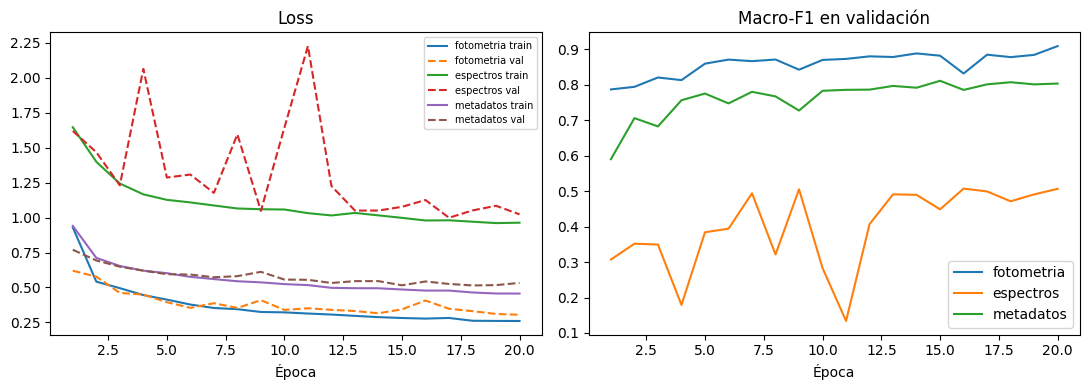

,parametros,segundos_entrenamiento,mejor_epoca_val
fotometria,19338.0,442.6,20.0
espectros,28618.0,353.8,16.0
metadatos,11338.0,342.2,15.0


In [13]:
reporting.plot_history({n: fit_results[n]["history"] for n in NAMES}, path=OUT / "figures" / "curvas_entrenamiento.png")
plt.show()
cost = pd.DataFrame({n: {"parametros": fit_results[n]["n_parameters"],
                         "segundos_entrenamiento": round(fit_results[n]["train_seconds"], 1),
                         "mejor_epoca_val": fit_results[n]["best_epoch"]} for n in NAMES}).T
display(cost)    # costo de cómputo registrado (la planificación estimó ~30 h de GPU)

## 3. Evaluación en validación y test (modelo de la última época)

Se predice con `shuffle=False` para que las tres modalidades queden alineadas por índice. Se guardan probabilidades y predicciones.

In [14]:
MODEL_SELECTION = "last"    # "last" = como el Entregable 1 (principal). "best" = mejor macro-F1 de validación (complementaria).
for n in NAMES:
    runs.load_checkpoint_into(MODELS[n], OUT / "checkpoints" / f"{n}_{SUBSET}.pt", which=MODEL_SELECTION, device=DEVICE)

loaders = {s: datasets.make_dataloader(ds[s], shuffle=False) for s in ("train", "validation", "test")}
PRED, METRICS = {"validation": {}, "test": {}}, {"validation": {}, "test": {}}
for split in ("validation", "test"):
    for n in NAMES:
        out = runs.predict_proba(MODELS[n], loaders[split], DEVICE, FWD[n])
        PRED[split][n] = out
        runs.save_predictions(OUT / "predictions" / f"{n}_{SUBSET}_{split}_{MODEL_SELECTION}.npz", out)
        METRICS[split][n] = fusion.summarize_predictions(out["y_true"], out["y_pred"], config.CLASS_NAMES)
    fusion.check_alignment([PRED[split][n]["y_true"] for n in NAMES])
print("Etiquetas alineadas entre las tres modalidades en validación y test.")
display(reporting.summary_table({f"{n} ({s})": METRICS[s][n] for s in ("validation", "test") for n in NAMES}))

Etiquetas alineadas entre las tres modalidades en validación y test.


,accuracy,macro_f1
fotometria (validation),0.8917,0.9096
espectros (validation),0.6349,0.5067
metadatos (validation),0.8161,0.8039
fotometria (test),0.8902,0.9083
espectros (test),0.6571,0.5219
metadatos (test),0.8155,0.8034


In [15]:
# Referencia: resultados del Entregable 1 (notebook ejecutado, test de sub50, entrenado en sub50, última época, 1 corrida).
E1_REF = {"fotometria": (0.886, 0.897), "metadatos": (0.820, 0.788), "espectros": (0.609, 0.478)}
cmp = pd.DataFrame({n: {"E1 accuracy": E1_REF[n][0], "E1 macro-F1": E1_REF[n][1],
                        "E2 accuracy": METRICS["test"][n]["accuracy"], "E2 macro-F1": METRICS["test"][n]["macro_f1"]}
                    for n in NAMES}).T.round(3)
display(cmp)   # diferencias pequeñas = no determinismo entre corridas, no mejora real

,E1 accuracy,E1 macro-F1,E2 accuracy,E2 macro-F1
fotometria,0.886,0.897,0.890,0.908
espectros,0.609,0.478,0.657,0.522
metadatos,0.820,0.788,0.815,0.803



===== fotometria — test sub50 =====
              precision    recall  f1-score   support

        DSCT       1.00      0.92      0.96        24
          EA       0.88      0.84      0.86       160
          EB       0.80      0.76      0.78       160
          EW       0.81      0.79      0.80       160
        HADS       0.93      1.00      0.96        26
           M       1.00      1.00      1.00        22
         ROT       0.92      0.95      0.94       160
        RRAB       0.97      0.99      0.98       160
         RRC       0.81      0.87      0.84        79
          SR       0.96      0.97      0.97       160

    accuracy                           0.89      1111
   macro avg       0.91      0.91      0.91      1111
weighted avg       0.89      0.89      0.89      1111



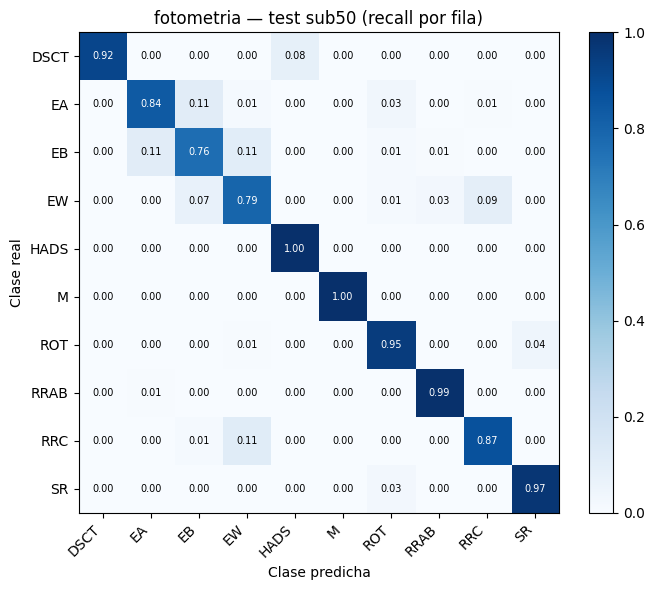


===== espectros — test sub50 =====
              precision    recall  f1-score   support

        DSCT       0.00      0.00      0.00        24
          EA       0.55      0.28      0.37       160
          EB       0.45      0.51      0.47       160
          EW       0.50      0.90      0.64       160
        HADS       0.00      0.00      0.00        26
           M       0.77      0.45      0.57        22
         ROT       0.86      0.86      0.86       160
        RRAB       0.86      0.67      0.75       160
         RRC       0.63      0.66      0.65        79
          SR       0.86      0.97      0.91       160

    accuracy                           0.66      1111
   macro avg       0.55      0.53      0.52      1111
weighted avg       0.65      0.66      0.63      1111



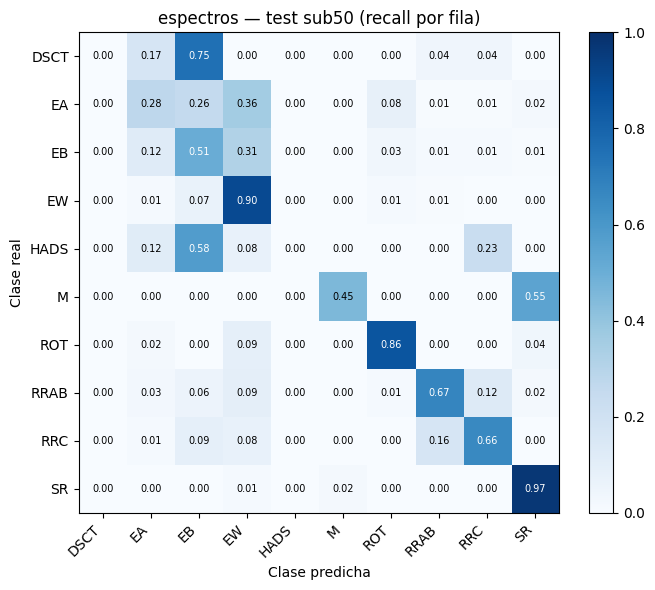


===== metadatos — test sub50 =====
              precision    recall  f1-score   support

        DSCT       0.74      0.71      0.72        24
          EA       0.72      0.71      0.72       160
          EB       0.65      0.57      0.61       160
          EW       0.70      0.81      0.75       160
        HADS       0.85      0.65      0.74        26
           M       0.77      0.91      0.83        22
         ROT       0.90      0.95      0.93       160
        RRAB       0.97      0.90      0.93       160
         RRC       0.80      0.89      0.84        79
          SR       0.98      0.95      0.97       160

    accuracy                           0.82      1111
   macro avg       0.81      0.80      0.80      1111
weighted avg       0.82      0.82      0.81      1111



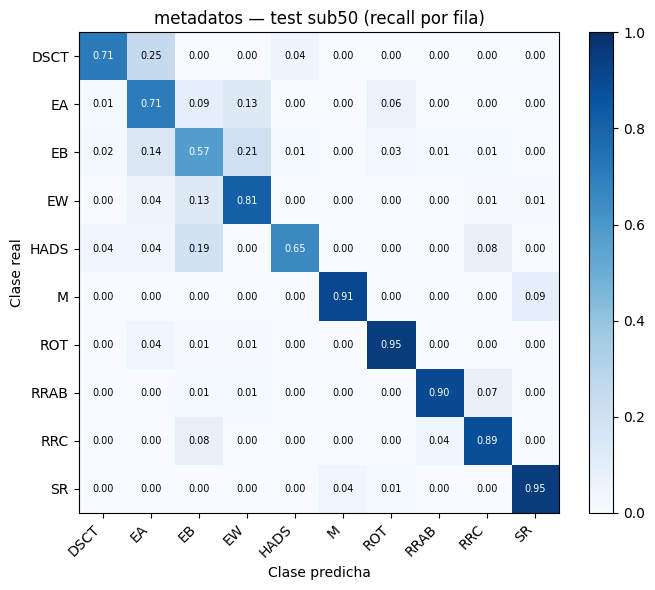

In [16]:
for n in NAMES:
    print(f"\n===== {n} — test {SUBSET} =====")
    print(METRICS["test"][n]["report_text"])
    reporting.plot_confusion_matrix(METRICS["test"][n]["confusion_matrix"], title=f"{n} — test {SUBSET} (recall por fila)",
                                    path=OUT / "figures" / f"cm_{n}_{SUBSET}_test.png")
    plt.show()

## 4. Fusión por votación (2-de-3)

Fusión tardía: cada modelo unimodal emite su clase y se decide por mayoría. Si los tres difieren, se aplica la regla de desempate, **elegida con validación**.

In [17]:
val_f1 = {n: METRICS["validation"][n]["macro_f1"] for n in NAMES}
PRIORITY = fusion.rank_by_validation(val_f1)
print("Prioridad por macro-F1 de validación:", PRIORITY)

def run_vote(split, rule):
    preds = {n: PRED[split][n]["y_pred"] for n in NAMES}
    probs = {n: PRED[split][n]["probs"] for n in NAMES}
    vote = fusion.hard_vote(preds, tie_break=rule, priority=PRIORITY, probs=probs)
    y_true = PRED[split][NAMES[0]]["y_true"]
    return vote, fusion.summarize_predictions(y_true, vote["y_pred"], config.CLASS_NAMES), y_true, preds

# 1) Elegir la regla de desempate SOLO con validación
val_scores = {}
for rule in fusion.TIE_BREAKS:
    _, m, _, _ = run_vote("validation", rule)
    val_scores[rule] = m["macro_f1"]
CHOSEN_RULE = max(val_scores, key=val_scores.get)
print("Macro-F1 de validación por regla de desempate:", {k: round(v, 4) for k, v in val_scores.items()})
print("Regla elegida (validación):", CHOSEN_RULE)

Prioridad por macro-F1 de validación: ['fotometria', 'metadatos', 'espectros']
Macro-F1 de validación por regla de desempate: {'priority': 0.9023, 'confidence': 0.9024, 'error': 0.8726}
Regla elegida (validación): confidence


In [18]:
# 2) Resultados en test: la regla elegida es la principal; las otras se muestran por transparencia.
VOTE, VOTE_METRICS = {}, {}
for rule in fusion.TIE_BREAKS:
    VOTE[rule], VOTE_METRICS[rule], y_true_test, preds_test = run_vote("test", rule)
tbl = reporting.summary_table({**{f"{n} (unimodal)": METRICS["test"][n] for n in NAMES},
                               **{f"votación 2-de-3, desempate={r}" + (" [elegida]" if r == CHOSEN_RULE else ""): VOTE_METRICS[r]
                                  for r in fusion.TIE_BREAKS}})
display(tbl)

,accuracy,macro_f1
fotometria (unimodal),0.8902,0.9083
espectros (unimodal),0.6571,0.5219
metadatos (unimodal),0.8155,0.8034
"votación 2-de-3, desempate=priority",0.8785,0.8909
"votación 2-de-3, desempate=confidence [elegida]",0.8776,0.8872
"votación 2-de-3, desempate=error",0.8479,0.8646


In [19]:
# Cuántas veces coinciden los modelos y cuánto acierta la votación en cada caso.
ag = fusion.agreement_analysis(y_true_test, preds_test, VOTE[CHOSEN_RULE])
print(json.dumps(ag, indent=2, ensure_ascii=False))

{
  "n": 1111,
  "oracle_any_model_correct": 0.9594959495949595,
  "per_modality_accuracy": {
    "fotometria": 0.8901890189018902,
    "espectros": 0.6570657065706571,
    "metadatos": 0.8154815481548154
  },
  "cases": {
    "unánime": {
      "n": 633,
      "fraccion": 0.5697569756975698,
      "accuracy_votacion": 0.9747235387045814
    },
    "mayoría 2-de-3": {
      "n": 418,
      "fraccion": 0.37623762376237624,
      "accuracy_votacion": 0.777511961722488
    },
    "los 3 difieren": {
      "n": 60,
      "fraccion": 0.054005400540054004,
      "accuracy_votacion": 0.55
    }
  }
}


              precision    recall  f1-score   support

        DSCT       1.00      0.88      0.93        24
          EA       0.83      0.76      0.79       160
          EB       0.77      0.66      0.71       160
          EW       0.75      0.89      0.81       160
        HADS       0.95      0.81      0.88        26
           M       0.91      0.95      0.93        22
         ROT       0.90      0.99      0.94       160
        RRAB       0.97      0.97      0.97       160
         RRC       0.92      0.90      0.91        79
          SR       0.98      0.99      0.98       160

    accuracy                           0.88      1111
   macro avg       0.90      0.88      0.89      1111
weighted avg       0.88      0.88      0.88      1111



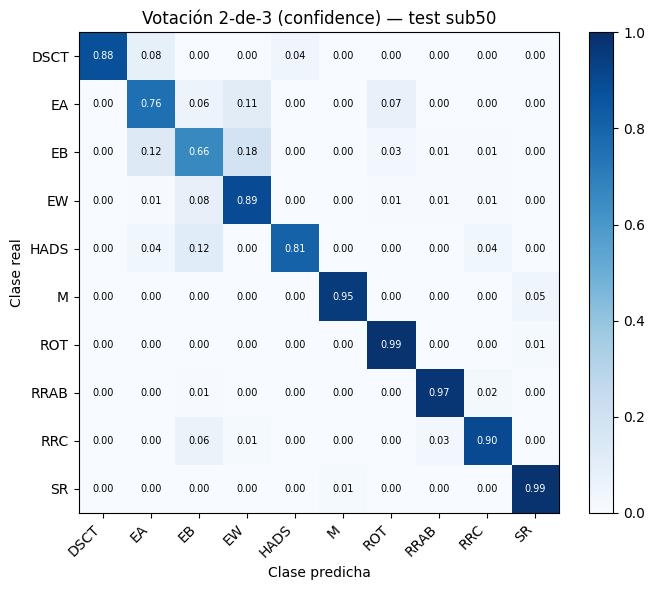

,fotometria,espectros,metadatos,votación
DSCT,0.957,0.000,0.723,0.933
EA,0.856,0.367,0.715,0.793
EB,0.780,0.474,0.607,0.709
EW,0.804,0.640,0.749,0.815
HADS,0.963,0.000,0.739,0.875
M,1.000,0.571,0.833,0.933
ROT,0.935,0.859,0.927,0.943
RRAB,0.981,0.751,0.932,0.975
RRC,0.841,0.646,0.843,0.910
SR,0.966,0.912,0.965,0.984


In [20]:
print(VOTE_METRICS[CHOSEN_RULE]["report_text"])
reporting.plot_confusion_matrix(VOTE_METRICS[CHOSEN_RULE]["confusion_matrix"],
                                title=f"Votación 2-de-3 ({CHOSEN_RULE}) — test {SUBSET}", path=OUT / "figures" / f"cm_votacion_{SUBSET}_test.png")
plt.show()
f1_tbl = reporting.per_class_table({**{n: METRICS["test"][n] for n in NAMES}, "votación": VOTE_METRICS[CHOSEN_RULE]}, "f1").round(3)
display(f1_tbl)   # análisis por clase (objetivo específico v)

In [21]:
# Referencia complementaria (NO es la regla 2-de-3 prometida): promedio de probabilidades.
soft_pred = fusion.soft_vote({n: PRED["test"][n]["probs"] for n in NAMES})
soft_m = fusion.summarize_predictions(y_true_test, soft_pred, config.CLASS_NAMES)
print(f"Voto suave (promedio de probabilidades) — test: accuracy={soft_m['accuracy']:.4f} macro-F1={soft_m['macro_f1']:.4f}")

Voto suave (promedio de probabilidades) — test: accuracy=0.9082 macro-F1=0.9167


## 5. Extracción de embeddings (insumo del Entregable 3)

Misma secuencia que en el Entregable 1 pero ahora ejecutada con los modelos entrenados. `shuffle=False` para alinear por índice. Nota metodológica: los embeddings de *train* salen de codificadores entrenados con esos mismos objetos, por lo que son «vistos»; hay que declararlo cuando se entrene la cabeza de concatenación.

In [22]:
EMB = {s: {} for s in ("train", "validation", "test")}
for s in EMB:
    for n in NAMES:
        EMB[s][n] = embeddings.extract_embeddings(MODELS[n], loaders[s], DEVICE, FWD[n])
        embeddings.save_embeddings(str(OUT / "embeddings" / f"{n}_{SUBSET}_{s}.npz"), EMB[s][n]["embeddings"], EMB[s][n]["labels"])
    fusion.check_alignment([EMB[s][n]["labels"] for n in NAMES])
    fused = embeddings.concatenate_modalities(EMB[s]["fotometria"]["embeddings"], EMB[s]["espectros"]["embeddings"],
                                              EMB[s]["metadatos"]["embeddings"], EMB[s]["fotometria"]["labels"])
    embeddings.save_embeddings(str(OUT / "embeddings" / f"fused_{SUBSET}_{s}.npz"), fused["embeddings"], fused["labels"])
    print(s, "-> fusionado:", fused["embeddings"].shape, "(orden: fotometría | espectros | metadatos)")

Guardado: outputs_e2/embeddings/fotometria_sub50_train.npz  (embeddings: (8526, 64), labels: (8526,))
Guardado: outputs_e2/embeddings/espectros_sub50_train.npz  (embeddings: (8526, 64), labels: (8526,))
Guardado: outputs_e2/embeddings/metadatos_sub50_train.npz  (embeddings: (8526, 64), labels: (8526,))
Guardado: outputs_e2/embeddings/fused_sub50_train.npz  (embeddings: (8526, 192), labels: (8526,))
train -> fusionado: (8526, 192) (orden: fotometría | espectros | metadatos)
Guardado: outputs_e2/embeddings/fotometria_sub50_validation.npz  (embeddings: (1071, 64), labels: (1071,))
Guardado: outputs_e2/embeddings/espectros_sub50_validation.npz  (embeddings: (1071, 64), labels: (1071,))
Guardado: outputs_e2/embeddings/metadatos_sub50_validation.npz  (embeddings: (1071, 64), labels: (1071,))
Guardado: outputs_e2/embeddings/fused_sub50_validation.npz  (embeddings: (1071, 192), labels: (1071,))
validation -> fusionado: (1071, 192) (orden: fotometría | espectros | metadatos)
Guardado: outputs_e

## 6. Resumen guardado

In [23]:
def clean(m):
    return {"accuracy": float(m["accuracy"]), "macro_f1": float(m["macro_f1"]),
            "per_class_f1": {c: float(v["f1"]) for c, v in m["per_class"].items()}}

results = {
    "subset": SUBSET, "seed": config.SEED, "model_selection": MODEL_SELECTION, "device": DEVICE,
    "torch": torch.__version__, "epochs": config.NUM_EPOCHS, "lr": config.LEARNING_RATE, "batch_size": config.BATCH_SIZE,
    "class_distribution_train": dist["train"].to_dict(),
    "cost": cost.to_dict(orient="index"),
    "unimodal": {s: {n: clean(METRICS[s][n]) for n in NAMES} for s in ("validation", "test")},
    "vote": {"priority_by_val": PRIORITY, "chosen_tie_break": CHOSEN_RULE,
             "val_macro_f1_by_rule": {k: float(v) for k, v in val_scores.items()},
             "test": {r: clean(VOTE_METRICS[r]) for r in fusion.TIE_BREAKS},
             "agreement_test": ag},
    "soft_vote_test": {"accuracy": float(soft_m["accuracy"]), "macro_f1": float(soft_m["macro_f1"])},
}
with open(OUT / "results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)
print("Guardado:", OUT / "results.json")

Guardado: outputs_e2/results.json


**Fuera de este entregable (pendiente a propósito):** fusión por concatenación y transferencia desde AstroM3-CLIP (Entregable 3); ablación de canales de la fotometría y cuenta de FLOPs (se deja para el final).